Visualize decision boundaries for classifiers in multi-dimensional space, using techniques such as PCA or t-SNE for dimensionality reduction to interpret model behavior and identify areas of uncertainty.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import HistGradientBoostingClassifier

In [3]:
np.random.seed(42)
n_samples = 1200
n_features = 8

In [4]:
X_raw, y_raw = make_classification(
    n_samples=n_samples,
    n_features=n_features,
    n_informative=6,
    n_redundant=2,
    n_classes=3,
    weights=[0.50, 0.30, 0.20],
    random_state=42
)

In [5]:
feature_cols = [f"biomarker_{i+1}" for i in range(n_features)]
X = pd.DataFrame(X_raw, columns=feature_cols)
y = y_raw

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

In [7]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [8]:
model = HistGradientBoostingClassifier(max_iter=100, random_state=42)
model.fit(X_train_scaled, y_train)

c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

HistGradientBoostingClassifier(random_state=42)

In [9]:
pca = PCA(n_components=2, random_state=42)
X_test_pca = pca.fit_transform(X_test_scaled)

In [10]:
model_2d = HistGradientBoostingClassifier(max_iter=100, random_state=42)
model_2d.fit(X_test_pca, y_test)

HistGradientBoostingClassifier(random_state=42)

In [11]:
h = 0.05
x_min, x_max = X_test_pca[:, 0].min() - 1, X_test_pca[:, 0].max() + 1
y_min, y_max = X_test_pca[:, 1].min() - 1, X_test_pca[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
grid_points = np.c_[xx.ravel(), yy.ravel()]

In [12]:
grid_probs = model_2d.predict_proba(grid_points)
grid_preds = np.argmax(grid_probs, axis=1)
grid_entropy = -np.sum(grid_probs * np.log(grid_probs + 1e-12), axis=1)

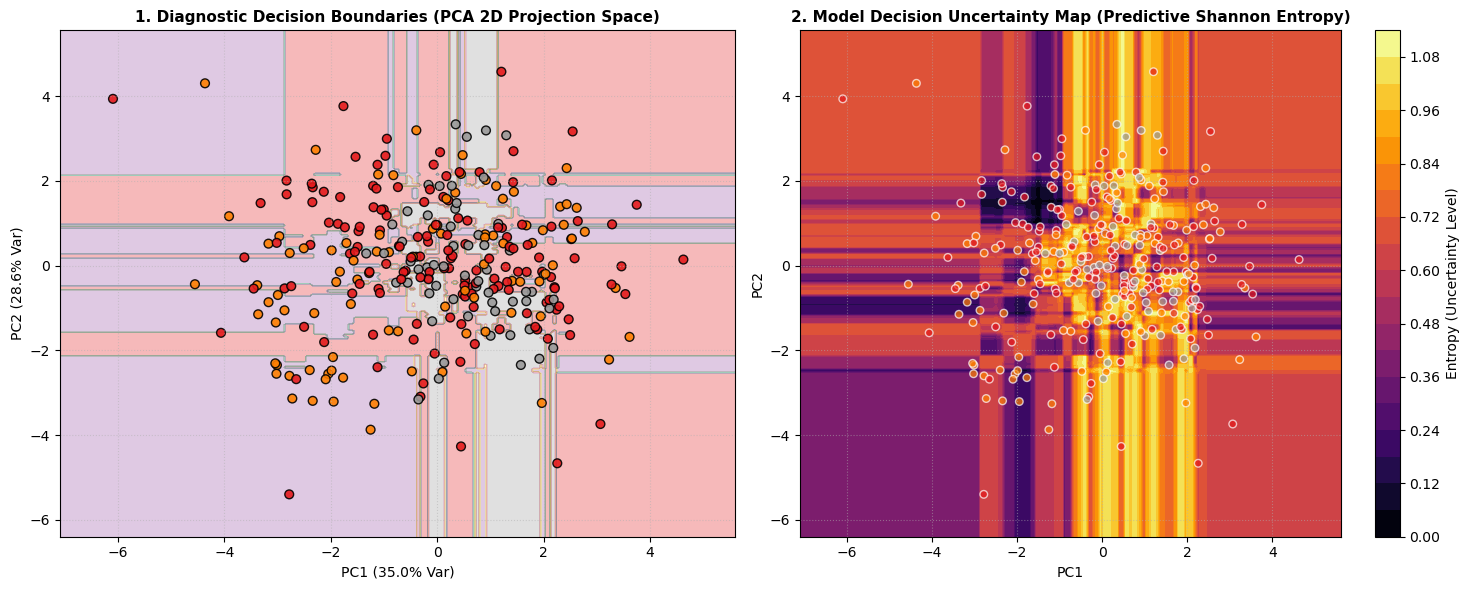

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

Z_preds = grid_preds.reshape(xx.shape)
axes[0].contourf(xx, yy, Z_preds, alpha=0.3, cmap='Set1')
scatter1 = axes[0].scatter(
    X_test_pca[:, 0], X_test_pca[:, 1], 
    c=y_test, cmap='Set1', edgecolors='k', alpha=0.9, s=40
)
axes[0].set_title("1. Diagnostic Decision Boundaries (PCA 2D Projection Space)", fontsize=11, fontweight='bold')
axes[0].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} Var)")
axes[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} Var)")
axes[0].grid(True, linestyle=':', alpha=0.5)

Z_entropy = grid_entropy.reshape(xx.shape)
contour2 = axes[1].contourf(xx, yy, Z_entropy, levels=20, cmap='inferno')
axes[1].scatter(
    X_test_pca[:, 0], X_test_pca[:, 1], 
    c=y_test, cmap='Set1', edgecolors='w', alpha=0.7, s=30
)
axes[1].set_title("2. Model Decision Uncertainty Map (Predictive Shannon Entropy)", fontsize=11, fontweight='bold')
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")
axes[1].grid(True, linestyle=':', alpha=0.5)

fig.colorbar(contour2, ax=axes[1], label="Entropy (Uncertainty Level)")
plt.tight_layout()
plt.show()